# 02 Exploratory data analysis: Delhi AQI, 2015 to 2019

**Syllabus unit:** Data wrangling, exploratory part (univariate, bivariate, multivariate analysis).
**Tutorial items:** 1 (classification, tabulation, graphs), 2 (central tendency, dispersion, skewness, kurtosis),
3 (point and interval estimates), 4 (correlation).
**Input:** `data/processed/aqi_delhi_clean.csv` from notebook 01.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from src.utils import *
set_plot_style()

df = load_clean()
df["Season"] = pd.Categorical(df["Season"], SEASONS, ordered=True)
print(df.shape, df["Date"].min().date(), "to", df["Date"].max().date())
BUCKET_COLORS = {"Good": "#2e9e44", "Satisfactory": "#9acd32", "Moderate": "#f2c12e",
                 "Poor": "#f08a24", "Very Poor": "#d7301f", "Severe": "#7f0000"}

(1826, 19) 2015-01-01 to 2019-12-31


## 1. Classification and tabulation (tutorial item 1)
### Frequency table of the official AQI bands

In [2]:
freq = (df["AQI_Bucket"].value_counts().reindex(BUCKETS).fillna(0).astype(int).to_frame("Days"))
pct = freq["Days"] / freq["Days"].sum() * 100
freq["% of days"] = pct.round(1)
freq["Cumulative %"] = pct.cumsum().round(1)
freq.loc["Total"] = [int(freq["Days"].sum()), 100.0, np.nan]
freq["Days"] = freq["Days"].astype(int)
save_table(freq.reset_index(names="AQI band"), "frequency_aqi_band")
freq

,Days,% of days,Cumulative %
AQI_Bucket,,,
Good,23,1.3,1.3
Satisfactory,139,7.6,8.9
Moderate,423,23.2,32.0
Poor,507,27.8,59.8
Very Poor,498,27.3,87.1
Severe,236,12.9,100.0
Total,1826,100.0,NaN


**Reading the table.** Only 162 of 1,826 days (8.9%) were Good or Satisfactory. Poor, Very Poor and Severe
together cover 68.0% of days, and 12.9% (236 days) were Severe, the band in which even healthy people are affected.

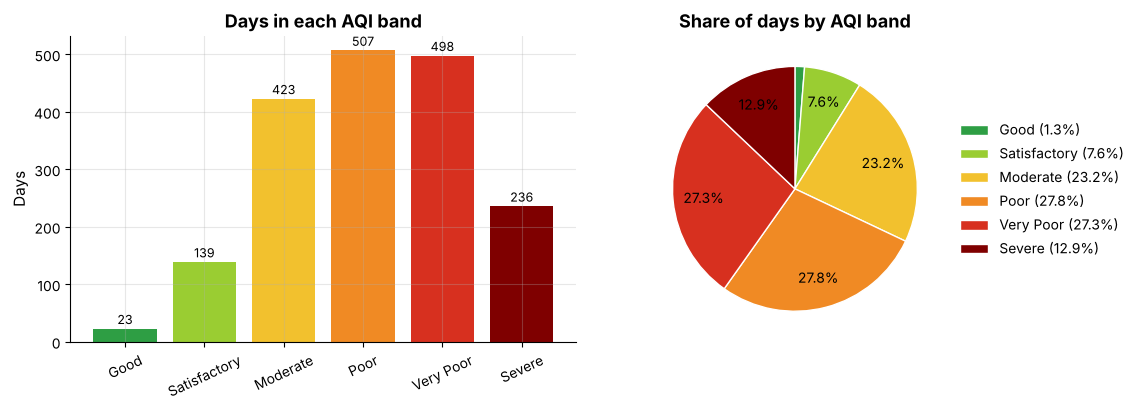

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
f = freq.drop("Total")
ax[0].bar(f.index, f["Days"], color=[BUCKET_COLORS[b] for b in f.index])
for i, v in enumerate(f["Days"]):
    ax[0].text(i, v + 8, f"{v}", ha="center", fontsize=9)
ax[0].set(title="Days in each AQI band", ylabel="Days")
ax[0].tick_params(axis="x", rotation=25)
wedges, _, _ = ax[1].pie(f["Days"], autopct=lambda v: f"{v:.1f}%" if v > 5 else "", pctdistance=.75,
                         colors=[BUCKET_COLORS[b] for b in f.index], startangle=90, counterclock=False,
                         wedgeprops={"linewidth": 1, "edgecolor": "white"})
ax[1].legend(wedges, [f"{b} ({v:.1f}%)" for b, v in zip(f.index, f["% of days"])], loc="center left",
             bbox_to_anchor=(1, .5))
ax[1].set_title("Share of days by AQI band")
plt.tight_layout(); save_figure(fig, "02_band_bar_pie"); plt.show()

### Two-way table: season by AQI band (row percentages)

In [4]:
ct = pd.crosstab(df["Season"], df["AQI_Bucket"], normalize="index").reindex(columns=BUCKETS).mul(100).round(1)
ct["Days"] = df["Season"].value_counts().reindex(SEASONS)
save_table(ct.reset_index(), "crosstab_season_band")
ct

AQI_Bucket,Good,Satisfactory,Moderate,Poor,Very Poor,Severe,Days
Season,,,,,,,
Winter,0.0,0.0,4.7,17.3,53.2,24.8,451
Summer,0.0,0.2,20.4,49.3,25.0,5.0,460
Monsoon,3.8,22.3,46.6,22.8,3.8,0.8,610
Post-monsoon,0.0,0.7,7.9,20.7,39.3,31.5,305


Winter has **no** Good or Satisfactory day in five years and 78% of winter days are Very Poor or Severe. Post-monsoon
(October-November, the crop-residue burning and Diwali period) has the largest Severe share at 31.5%. Monsoon is the
only clean season: 26% of its days are Good or Satisfactory.

In [5]:
group_tab = df["AQI_Group"].value_counts().reindex(GROUPS).to_frame("Days")
group_tab["%"] = (group_tab["Days"] / len(df) * 100).round(1)
poor_tab = df["Poor_Flag"].value_counts().sort_index().rename({0: "Not Poor (AQI ≤ 200)", 1: "Poor or worse (AQI > 200)"}).to_frame("Days")
poor_tab["%"] = (poor_tab["Days"] / len(df) * 100).round(1)
display(group_tab, poor_tab)

,Days,%
AQI_Group,,
Low,162,8.9
Moderate,423,23.2
High,1241,68.0


,Days,%
Poor_Flag,,
Not Poor (AQI ≤ 200),585,32.0
Poor or worse (AQI > 200),1241,68.0


### Graphs over time

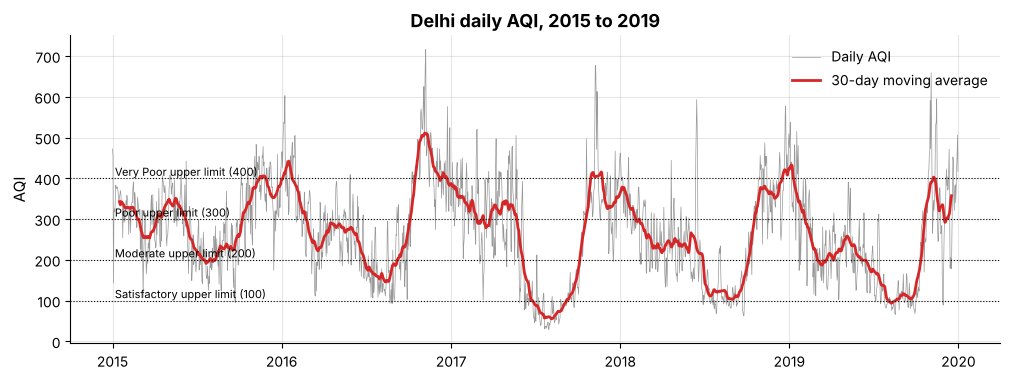

In [6]:
s = df.set_index("Date")["AQI"]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(s.index, s, lw=.5, color="0.6", label="Daily AQI")
ax.plot(s.index, s.rolling(30, center=True).mean(), lw=2, color="C3", label="30-day moving average")
for y0, lab in [(100, "Satisfactory"), (200, "Moderate"), (300, "Poor"), (400, "Very Poor")]:
    ax.axhline(y0, ls=":", lw=.8, color="k")
    ax.text(s.index[5], y0 + 6, f"{lab} upper limit ({y0})", fontsize=8)
ax.set(title="Delhi daily AQI, 2015 to 2019", ylabel="AQI")
ax.legend(loc="upper right")
save_figure(fig, "02_aqi_timeseries"); plt.show()

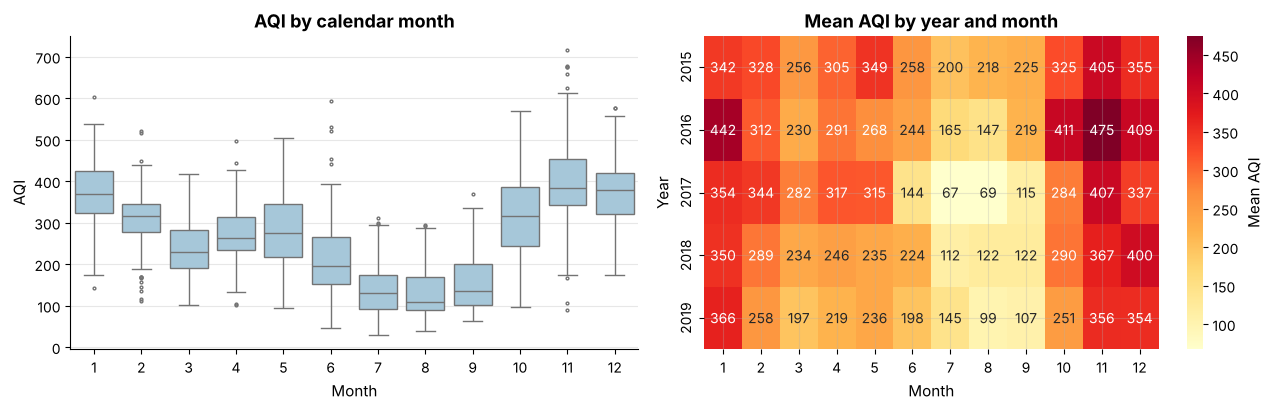

Month,1,2,3,4,5,6,7,8,9,10,11,12
Mean,371.0,306.0,240.0,276.0,281.0,214.0,138.0,131.0,157.0,312.0,402.0,371.0
Median,368.0,315.0,230.0,262.0,276.0,195.0,130.0,109.0,136.0,317.0,384.0,379.0
90th percentile,467.0,372.0,341.0,378.0,394.0,327.0,224.0,230.0,267.0,428.0,538.0,459.0


In [7]:
monthly_profile = df.groupby("Month")["AQI"].agg(["mean", "median", lambda x: x.quantile(.9)])
monthly_profile.columns = ["Mean", "Median", "90th percentile"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
sns.boxplot(data=df, x="Month", y="AQI", color="#9ecae1", fliersize=2, ax=ax[0])
ax[0].set(title="AQI by calendar month")
year_month = df.pivot_table(index="Year", columns="Month", values="AQI", aggfunc="mean")
sns.heatmap(year_month, cmap="YlOrRd", annot=True, fmt=".0f", cbar_kws={"label": "Mean AQI"}, ax=ax[1])
ax[1].set(title="Mean AQI by year and month")
plt.tight_layout(); save_figure(fig, "02_month_box_heatmap"); plt.show()
monthly_profile.round(0).T

The seasonal cycle is very regular: AQI bottoms out in July-August (mean about 131 to 138) when monsoon rain washes
particles out, and peaks in November (mean 402) when stubble burning, low wind speed and a shallow winter
boundary layer trap pollution. The heatmap also shows each year's winter getting slightly less extreme.

## 2. Univariate analysis: central tendency, dispersion and shape (tutorial item 2)
Skewness is the third standardised moment and kurtosis the fourth; *excess* kurtosis (Fisher definition, normal = 0)
is reported. The mode of a continuous variable is estimated as the peak of a kernel density estimate, which is more
meaningful than the most repeated decimal value.

In [8]:
def kde_mode(x):
    x = np.asarray(x, float)
    grid = np.linspace(x.min(), x.max(), 2000)
    return float(grid[np.argmax(stats.gaussian_kde(x)(grid))])

def describe(x: pd.Series) -> dict:
    return {"n": len(x), "Mean": x.mean(), "Median": x.median(), "Mode (KDE)": kde_mode(x),
            "Std dev": x.std(), "Variance": x.var(), "CV %": x.std() / x.mean() * 100,
            "Min": x.min(), "Q1": x.quantile(.25), "Q3": x.quantile(.75), "Max": x.max(),
            "IQR": x.quantile(.75) - x.quantile(.25),
            "Skewness": stats.skew(x), "Excess kurtosis": stats.kurtosis(x)}

VARS = ["PM2.5", "PM10", "AQI"]
desc = pd.DataFrame({v: describe(df[v]) for v in VARS}).T
save_table(desc.round(3).reset_index(names="Variable"), "descriptive_overall")
desc.round(2)

,n,Mean,Median,Mode (KDE),Std dev,Variance,CV %,Min,Q1,Q3,Max,IQR,Skewness,Excess kurtosis
PM2.5,1826.0,120.37,97.65,63.16,81.92,6711.39,68.06,16.93,59.57,159.77,463.35,100.20,1.39,2.12
PM10,1826.0,235.74,219.41,190.27,121.04,14651.71,51.35,39.76,137.68,315.79,621.72,178.11,0.62,-0.04
AQI,1826.0,266.33,266.00,309.78,119.77,14344.78,44.97,29.00,172.25,352.00,716.00,179.75,0.26,-0.35


In [9]:
desc_all = pd.DataFrame({v: describe(df[v]) for v in POLLUTANTS}).T[["Mean", "Median", "Std dev", "CV %", "Skewness", "Excess kurtosis"]]
desc_all.round(2)

,Mean,Median,Std dev,CV %,Skewness,Excess kurtosis
PM2.5,120.37,97.65,81.92,68.06,1.39,2.12
PM10,235.74,219.41,121.04,51.35,0.62,-0.04
NO,40.50,28.84,33.36,82.38,1.66,2.49
NO2,52.50,49.19,22.44,42.74,0.97,1.03
NOx,60.47,54.54,37.68,62.31,1.05,1.17
NH3,42.72,39.02,17.43,40.80,2.08,7.12
CO,2.07,1.29,2.47,119.46,2.92,8.04
SO2,16.12,14.63,8.10,50.25,1.54,3.60
O3,51.14,44.06,26.13,51.10,1.53,2.73


In [10]:
by_season = []
for v in VARS:
    for sname, g in df.groupby("Season", observed=True):
        d = describe(g[v]); d.update({"Variable": v, "Season": sname}); by_season.append(d)
by_season = pd.DataFrame(by_season).set_index(["Variable", "Season"])[["n", "Mean", "Median", "Std dev", "CV %", "Skewness", "Excess kurtosis"]]
save_table(by_season.round(3).reset_index(), "descriptive_by_season")
by_season.round(2)

n    Mean  Median  Std dev   CV %  Skewness  Excess kurtosis
Variable Season                                                                      
PM2.5    Winter        451  187.87  177.32    70.20  37.37      0.69             0.36
         Summer        460   97.73   93.93    34.02  34.81      0.94             1.31
         Monsoon       610   54.72   50.92    26.15  47.78      2.02             9.57
         Post-monsoon  305  186.00  166.43    96.83  52.06      1.10             0.88
PM10     Winter        451  308.58  308.37   108.09  35.03      0.26            -0.44
         Summer        460  233.16  224.93    85.31  36.59      0.42             0.11
         Monsoon       610  143.00  122.21    83.35  58.29      1.90             6.03
         Post-monsoon  305  317.40  305.35   118.02  37.18      0.44            -0.13
AQI      Winter        451  350.79  349.00    80.42  22.93     -0.08             0.41
         Summer        460  265.30  257.50    77.61  29.26      0.38            -0.19
         Monsoon       610  159.64  142.50    80.40  50.36      1.16             2.31
         Post-monsoon  305  356.41  356.00   113.72  31.91      0.20             0.42

**Interpretation (one line each).**
* **PM2.5** - mean 120.4 above median 97.7, skewness 1.39 and excess kurtosis 2.12: strongly right-skewed with a
  heavy upper tail (a few extreme smog days). The typical day (KDE mode, about 63) is far below the mean.
* **PM10** - skewness 0.62, kurtosis about 0: moderately right-skewed, tails close to normal.
* **AQI** - mean 266.3 and median 266.0 almost equal, skewness 0.26, excess kurtosis -0.35: only slightly
  right-skewed and a little flatter than normal. The project pack expected a clearly right-skewed AQI; the data say
  otherwise. The reason is that AQI is a *piecewise-linear, compressed* transform of concentrations (each band
  squeezes a wider concentration range into 100 points), which pulls in the long tail of PM2.5.
* **By season** - monsoon is the most right-skewed for every variable (PM2.5 skewness 2.02): mostly clean days
  with occasional dust or early-burning episodes. Monsoon also has the highest relative spread (CV 50% for AQI).
* **CO** has the highest coefficient of variation (119%) and kurtosis (8.0), driven by very high readings in 2015.

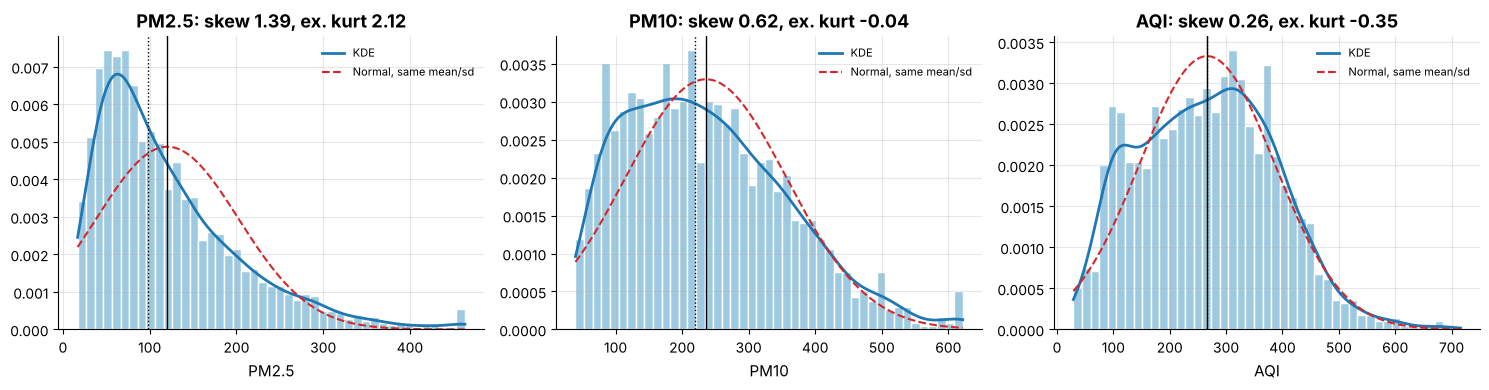

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, v in zip(ax, VARS):
    a.hist(df[v], bins=45, density=True, color="#9ecae1", edgecolor="white")
    xs = np.linspace(df[v].min(), df[v].max(), 300)
    a.plot(xs, stats.gaussian_kde(df[v])(xs), color="C0", lw=2, label="KDE")
    a.plot(xs, stats.norm.pdf(xs, df[v].mean(), df[v].std()), "--", color="C3", label="Normal, same mean/sd")
    a.axvline(df[v].mean(), color="k", lw=1); a.axvline(df[v].median(), color="k", ls=":", lw=1)
    a.set(title=f"{v}: skew {stats.skew(df[v]):.2f}, ex. kurt {stats.kurtosis(df[v]):.2f}", xlabel=v)
    a.legend(fontsize=8)
plt.tight_layout(); save_figure(fig, "02_histograms"); plt.show()

In [12]:
norm_tests = pd.DataFrame({v: {"D'Agostino K2": stats.normaltest(df[v])[0], "p-value": stats.normaltest(df[v])[1],
                               "Jarque-Bera": stats.jarque_bera(df[v])[0], "JB p-value": stats.jarque_bera(df[v])[1]}
                           for v in VARS}).T
norm_tests.round(4)

,D'Agostino K2,p-value,Jarque-Bera,JB p-value
PM2.5,440.7830,0.0,927.9276,0.0
PM10,99.4758,0.0,115.5382,0.0
AQI,32.9164,0.0,29.3042,0.0


All three variables reject normality (p < 0.001), as expected with n = 1,826 where even small departures are
detected. This matters for regression: the residuals, not the raw variables, are what must be checked (notebook 03).

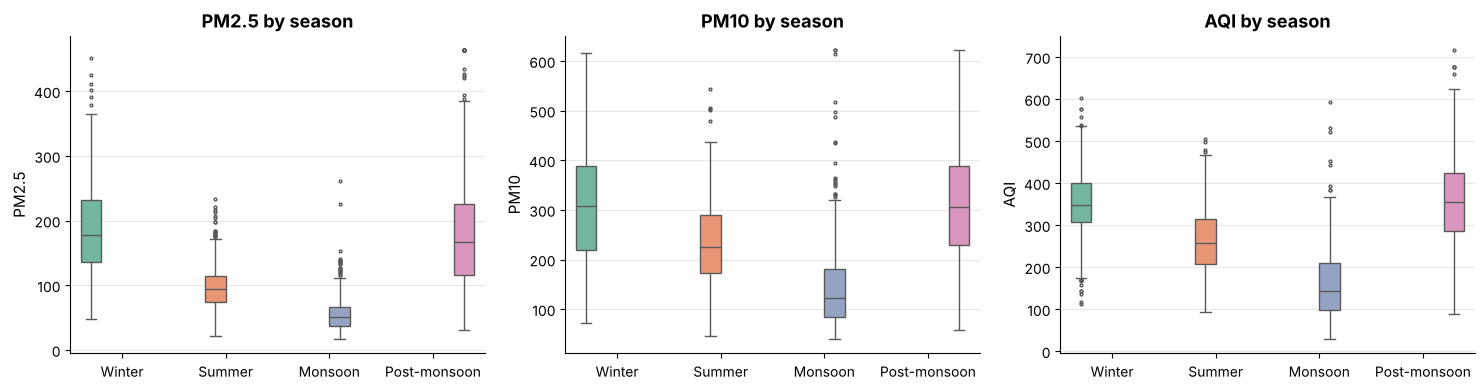

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, v in zip(ax, VARS):
    sns.boxplot(data=df, x="Season", y=v, hue="Season", palette="Set2", fliersize=2, ax=a, legend=False)
    a.set(title=f"{v} by season", xlabel="")
plt.tight_layout(); save_figure(fig, "02_season_boxplots"); plt.show()

**Do seasons really differ?** One-way ANOVA assumes normal groups with equal variance, which the tests above reject,
so the rank-based Kruskal-Wallis test is reported alongside it, with Levene's test for equal variances.

In [14]:
groups = [g["AQI"].values for _, g in df.groupby("Season", observed=True)]
F, p_anova = stats.f_oneway(*groups)
H, p_kw = stats.kruskal(*groups)
W, p_lev = stats.levene(*groups)
eps2 = (H - len(groups) + 1) / (len(df) - len(groups))
print(f"ANOVA:          F = {F:.1f}, p = {p_anova:.3g}")
print(f"Kruskal-Wallis: H = {H:.1f}, p = {p_kw:.3g}, effect size epsilon^2 = {eps2:.2f}")
print(f"Levene:         W = {W:.1f}, p = {p_lev:.3g}")

ANOVA:          F = 566.7, p = 4.08e-260
Kruskal-Wallis: H = 930.3, p = 2.34e-201, effect size epsilon^2 = 0.51
Levene:         W = 16.5, p = 1.31e-10


Both tests reject equal seasons overwhelmingly, and the effect is large: about half of the rank variation in AQI is
explained by season (epsilon-squared 0.51). Levene's test shows the variances also differ, so later models treat
season as a categorical variable and check heteroscedasticity.

## 3. Bivariate and multivariate analysis (tutorial item 4: correlation)

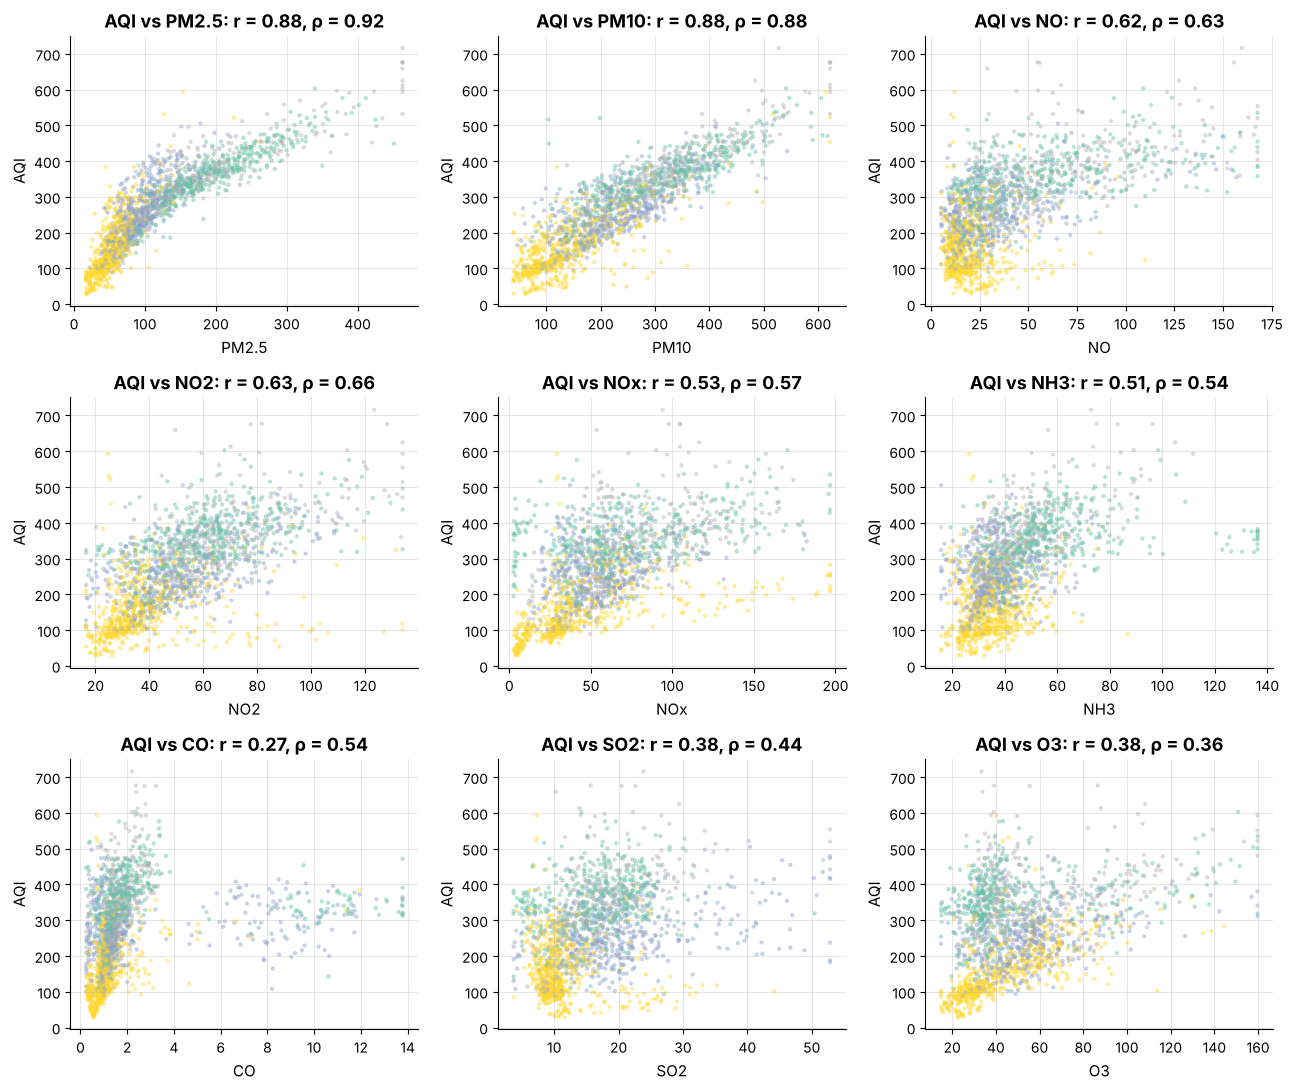

In [15]:
fig, axes = plt.subplots(3, 3, figsize=(13, 11))
for a, p in zip(axes.ravel(), POLLUTANTS):
    a.scatter(df[p], df["AQI"], s=5, alpha=.35, c=df["Season"].cat.codes, cmap="Set2")
    r = df[[p, "AQI"]].corr().iloc[0, 1]
    rho = stats.spearmanr(df[p], df["AQI"])[0]
    a.set(title=f"AQI vs {p}: r = {r:.2f}, ρ = {rho:.2f}", xlabel=p, ylabel="AQI")
plt.tight_layout(); save_figure(fig, "02_scatter_grid"); plt.show()

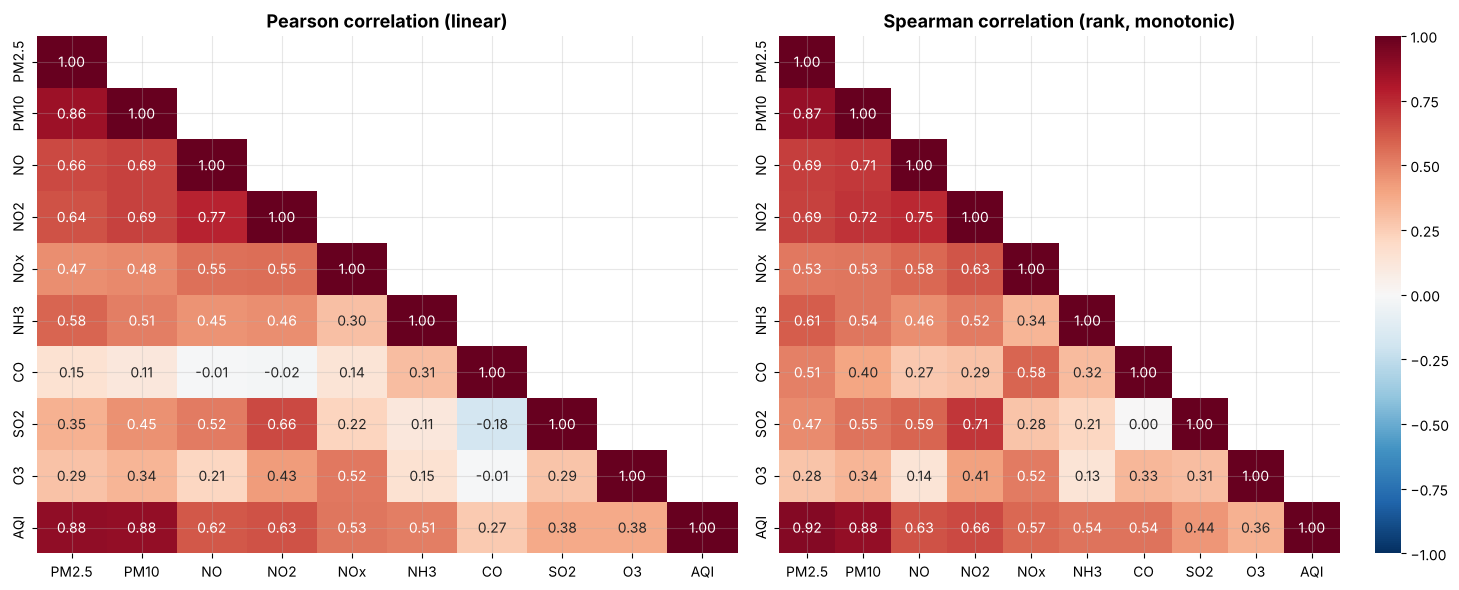

In [16]:
cols = POLLUTANTS + ["AQI"]
pear = df[cols].corr(method="pearson")
spear = df[cols].corr(method="spearman")
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
mask = np.triu(np.ones_like(pear, bool), 1)
sns.heatmap(pear, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax[0], cbar=False)
ax[0].set_title("Pearson correlation (linear)")
sns.heatmap(spear, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title("Spearman correlation (rank, monotonic)")
plt.tight_layout(); save_figure(fig, "02_correlation_heatmaps"); plt.show()
_ = save_table(pear.round(3).reset_index(names="Variable"), "correlation_pearson")
_ = save_table(spear.round(3).reset_index(names="Variable"), "correlation_spearman")

In [17]:
def corr_test(x, y, alpha=ALPHA):
    r, p = stats.pearsonr(x, y)
    z, se = np.arctanh(r), 1 / np.sqrt(len(x) - 3)
    zc = stats.norm.ppf(1 - alpha / 2)
    return r, p, np.tanh(z - zc * se), np.tanh(z + zc * se)

rows = []
for p in POLLUTANTS:
    r, pv, lo, hi = corr_test(df[p], df["AQI"])
    rho, prho = stats.spearmanr(df[p], df["AQI"])
    rows.append({"Pollutant": p, "Pearson r": r, "95% CI low": lo, "95% CI high": hi, "p (r)": pv,
                 "Spearman ρ": rho, "p (ρ)": prho})
corr_aqi = pd.DataFrame(rows).sort_values("Pearson r", ascending=False).set_index("Pollutant")
save_table(corr_aqi.round(4).reset_index(), "correlation_with_aqi")
corr_aqi.round(3)

,Pearson r,95% CI low,95% CI high,p (r),Spearman ρ,p (ρ)
Pollutant,,,,,,
PM2.5,0.884,0.874,0.894,0.0,0.920,0.0
PM10,0.881,0.870,0.891,0.0,0.878,0.0
NO2,0.634,0.606,0.661,0.0,0.662,0.0
NO,0.623,0.594,0.650,0.0,0.635,0.0
NOx,0.533,0.499,0.565,0.0,0.572,0.0
NH3,0.510,0.475,0.543,0.0,0.542,0.0
O3,0.382,0.342,0.420,0.0,0.355,0.0
SO2,0.378,0.338,0.416,0.0,0.440,0.0
CO,0.265,0.222,0.308,0.0,0.542,0.0


The confidence interval for each correlation uses Fisher's z transformation, z = artanh(r) with standard error
1/sqrt(n - 3).

**Reading the correlations.** PM2.5 (r = 0.88, ρ = 0.92) and PM10 (r = 0.88) are by far the strongest correlates of
AQI, as expected, since the particulate sub-index sets the AQI on most Delhi days. The nitrogen oxides come next
(0.53 to 0.63). CO is the interesting case: its Pearson r is only 0.27 but Spearman ρ is 0.54, so the relation is
monotonic but not linear, distorted by the very high 2015 readings. PM2.5 and PM10 are themselves highly correlated
(see heatmap), which warns of multicollinearity in the multiple regression.

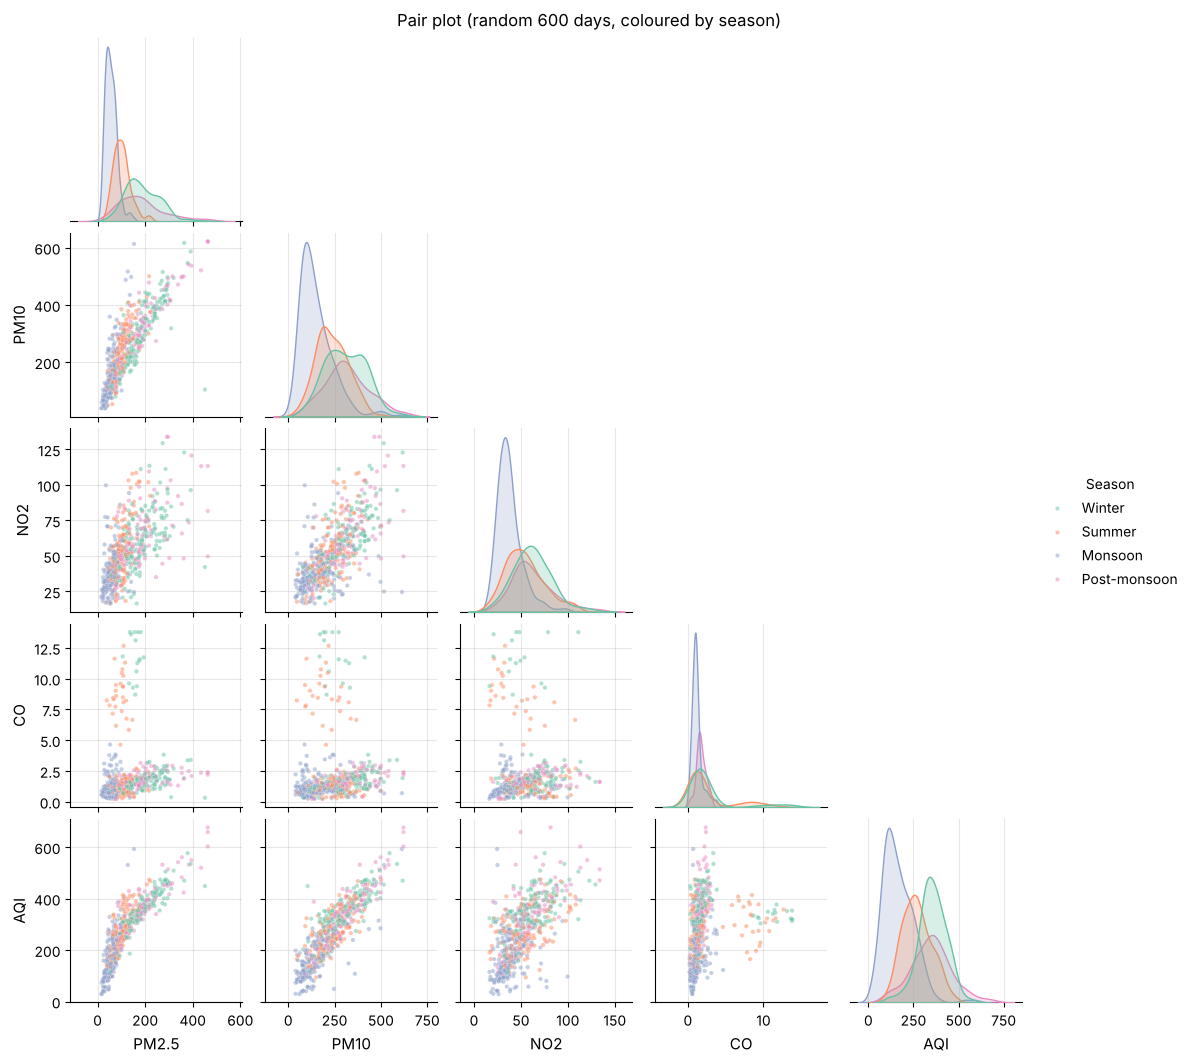

In [18]:
g = sns.pairplot(df.sample(600, random_state=SEED), vars=["PM2.5", "PM10", "NO2", "CO", "AQI"], hue="Season",
                 hue_order=SEASONS, palette="Set2", plot_kws={"s": 10, "alpha": .5}, corner=True, height=2.1)
g.figure.suptitle("Pair plot (random 600 days, coloured by season)", y=1.01)
save_figure(g.figure, "02_pairplot"); plt.show()

## 4. Point and interval estimates (tutorial item 3)
Three estimates with 95% intervals: mean AQI, median AQI and the share of Poor-or-worse days.

**A subtlety worth stating.** The classical formulas assume independent observations, but daily AQI is strongly
autocorrelated (today looks like yesterday). With lag-1 autocorrelation ρ, the *effective* sample size is roughly
n(1 - ρ)/(1 + ρ), so the honest interval is wider. Both versions are shown, plus a moving-block bootstrap, which
keeps the day-to-day dependence by resampling 30-day blocks.

In [19]:
x = df["AQI"].values
n = len(x)
mean, sd = x.mean(), x.std(ddof=1)
t_crit = stats.t.ppf(1 - ALPHA / 2, n - 1)
ci_mean = (mean - t_crit * sd / np.sqrt(n), mean + t_crit * sd / np.sqrt(n))
rho1 = pd.Series(x).autocorr(1)
n_eff = n * (1 - rho1) / (1 + rho1)
t_eff = stats.t.ppf(1 - ALPHA / 2, n_eff - 1)
ci_mean_eff = (mean - t_eff * sd / np.sqrt(n_eff), mean + t_eff * sd / np.sqrt(n_eff))

pp = df["Poor_Flag"].mean()
z = stats.norm.ppf(1 - ALPHA / 2)
ci_p_wald = (pp - z * np.sqrt(pp * (1 - pp) / n), pp + z * np.sqrt(pp * (1 - pp) / n))
den = 1 + z**2 / n
centre = (pp + z**2 / (2 * n)) / den
half = z * np.sqrt(pp * (1 - pp) / n + z**2 / (4 * n**2)) / den
ci_p_wilson = (centre - half, centre + half)

rng = np.random.default_rng(SEED)
B, block = 2000, 30
starts_max = n - block
boot_mean, boot_med, boot_p = [], [], []
pf = df["Poor_Flag"].values
for _ in range(B):
    idx = np.concatenate([np.arange(s0, s0 + block) for s0 in rng.integers(0, starts_max, n // block + 1)])[:n]
    boot_mean.append(x[idx].mean()); boot_med.append(np.median(x[idx])); boot_p.append(pf[idx].mean())
q = [ALPHA / 2 * 100, (1 - ALPHA / 2) * 100]

est = pd.DataFrame([
    {"Estimate": "Mean AQI", "Point": mean, "Method": "t interval (assumes independence)", "Low": ci_mean[0], "High": ci_mean[1]},
    {"Estimate": "Mean AQI", "Point": mean, "Method": f"t interval, effective n = {n_eff:.0f}", "Low": ci_mean_eff[0], "High": ci_mean_eff[1]},
    {"Estimate": "Mean AQI", "Point": mean, "Method": "moving-block bootstrap (30-day blocks)", "Low": np.percentile(boot_mean, q[0]), "High": np.percentile(boot_mean, q[1])},
    {"Estimate": "Median AQI", "Point": np.median(x), "Method": "moving-block bootstrap", "Low": np.percentile(boot_med, q[0]), "High": np.percentile(boot_med, q[1])},
    {"Estimate": "Share of Poor days", "Point": pp, "Method": "Wald (normal approximation)", "Low": ci_p_wald[0], "High": ci_p_wald[1]},
    {"Estimate": "Share of Poor days", "Point": pp, "Method": "Wilson score", "Low": ci_p_wilson[0], "High": ci_p_wilson[1]},
    {"Estimate": "Share of Poor days", "Point": pp, "Method": "moving-block bootstrap", "Low": np.percentile(boot_p, q[0]), "High": np.percentile(boot_p, q[1])},
])
print(f"lag-1 autocorrelation of daily AQI: {rho1:.3f}  ->  effective sample size about {n_eff:.0f} of {n} days")
save_table(est.round(4), "interval_estimates")
est.round(3)

lag-1 autocorrelation of daily AQI: 0.899  ->  effective sample size about 98 of 1826 days


,Estimate,Point,Method,Low,High
0,Mean AQI,266.334,t interval (assumes independence),260.836,271.831
1,Mean AQI,266.334,"t interval, effective n = 98",242.262,290.405
2,Mean AQI,266.334,moving-block bootstrap (30-day blocks),240.203,289.425
3,Median AQI,266.000,moving-block bootstrap,232.000,296.000
4,Share of Poor days,0.680,Wald (normal approximation),0.658,0.701
5,Share of Poor days,0.680,Wilson score,0.658,0.701
6,Share of Poor days,0.680,moving-block bootstrap,0.589,0.760


**Point and interval estimates.**
* Mean AQI is **266.3**. The textbook t-interval (260.8 to 271.8) is too narrow: the lag-1 autocorrelation is 0.90,
  so the 1,826 days carry about as much independent information as 98 independent days. The effective-n interval
  (242.3 to 290.4) and the block bootstrap (240.2 to 289.4) agree with each other and are about 4.4 times wider.
* The share of Poor-or-worse days is **68.0%**; the Wald and Wilson intervals (65.8% to 70.1%) agree because n is
  large and p is not extreme, but again the dependence-aware bootstrap (58.9% to 76.0%) is the honest one.
* Lesson for the viva: *interval width depends on independence, not just on n.*

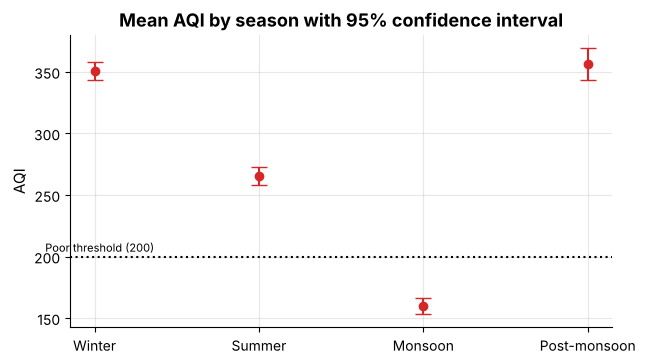

,n,Mean AQI,95% CI low,95% CI high,% Poor days
Season,,,,,
Winter,451,350.8,343.3,358.2,95.3
Summer,460,265.3,258.2,272.4,79.3
Monsoon,610,159.6,153.2,166.0,27.4
Post-monsoon,305,356.4,343.6,369.2,91.5


In [20]:
season_ci = []
for sname, g_ in df.groupby("Season", observed=True):
    v = g_["AQI"]; m_, s_ = v.mean(), v.std(ddof=1); k = len(v)
    tc = stats.t.ppf(1 - ALPHA / 2, k - 1)
    season_ci.append({"Season": sname, "n": k, "Mean AQI": m_, "95% CI low": m_ - tc * s_ / np.sqrt(k),
                      "95% CI high": m_ + tc * s_ / np.sqrt(k), "% Poor days": g_["Poor_Flag"].mean() * 100})
season_ci = pd.DataFrame(season_ci).set_index("Season")
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.errorbar(season_ci.index, season_ci["Mean AQI"],
            yerr=[season_ci["Mean AQI"] - season_ci["95% CI low"], season_ci["95% CI high"] - season_ci["Mean AQI"]],
            fmt="o", capsize=6, color="C3")
ax.axhline(200, ls=":", color="k"); ax.text(-0.3, 204, "Poor threshold (200)", fontsize=8)
ax.set(title="Mean AQI by season with 95% confidence interval", ylabel="AQI")
save_figure(fig, "02_season_ci"); plt.show()
season_ci.round(1)

Winter and post-monsoon have overlapping intervals (both about 350), and both are far above summer and monsoon.
95% of winter days and 92% of post-monsoon days are Poor or worse.

## 5. Year-on-year change and a first look at 2020

In [21]:
annual = df.groupby("Year").agg(mean_AQI=("AQI", "mean"), median_AQI=("AQI", "median"),
                                poor_days=("Poor_Flag", "sum"), severe_days=("AQI_Bucket", lambda b: (b == "Severe").sum()),
                                mean_PM25=("PM2.5", "mean"))
tau, p_tau = stats.kendalltau(df.groupby("Year")["AQI"].mean().index, df.groupby("Year")["AQI"].mean().values)
print(f"Kendall trend test on annual mean AQI (only 5 points, low power): tau = {tau:.2f}, p = {p_tau:.2f}")
annual.round(1)

Kendall trend test on annual mean AQI (only 5 points, low power): tau = -0.80, p = 0.08


,mean_AQI,median_AQI,poor_days,severe_days,mean_PM25
Year,,,,,
2015,297.0,303.0,313,33,117.3
2016,301.0,292.5,278,85,137.2
2017,252.2,274.0,231,44,124.0
2018,249.2,243.0,225,38,115.0
2019,232.1,209.0,194,36,108.2


Mean AQI fell from about 300 in 2015-16 to 232 in 2019 and Poor days from 313 to 194. The Kendall test is only
borderline (p = 0.08) because five annual points give little power, but the direction is consistent with the
Graded Response Action Plan (2017) and the end of the 2016 peak. A falling level is something the forecasting
models in notebook 05 must handle (a trend component).

In [22]:
h20 = pd.read_csv(DATA_2020, parse_dates=["Date"])
spring = lambda d: d[d["Date"].dt.month.isin([3, 4, 5])]
before = spring(df).groupby("Year")["AQI"].mean()
lock = spring(h20)["AQI"].mean()
print("Mean AQI, March to May:")
print(before.round(1).to_string())
print(f"2020 (lockdown from 25 March): {lock:.1f}  ->  {100 * (lock / before.mean() - 1):+.0f}% vs the 2015-19 average")

Mean AQI, March to May:
Year
2015    303.3
2016    262.7
2017    304.7
2018    238.2
2019    217.5
2020 (lockdown from 25 March): 132.7  ->  -50% vs the 2015-19 average


## 6. What the exploration shows
| Question | Answer from the data |
| --- | --- |
| How bad is Delhi's air? | 68% of days Poor or worse; 12.9% Severe; only 8.9% Good or Satisfactory |
| Shape of the distributions | PM2.5 strongly right-skewed (1.39); AQI nearly symmetric (0.26) because the AQI scale compresses high concentrations |
| Seasonality | Huge: Kruskal-Wallis ε² = 0.51; worst Nov (mean 402) and winter/post-monsoon (~350), best Jul-Aug (~135) |
| Main drivers (correlation) | PM2.5 (r = 0.88) and PM10 (0.88), then NO2 and NO (~0.63) |
| Point estimate of mean AQI | 266.3, 95% CI 242 to 290 once autocorrelation is respected |
| Share of Poor days | 68.0%, dependence-aware 95% CI 59% to 76% |
| Trend | Improving: annual mean 297 (2015) to 232 (2019) |
| COVID-19 | March-May 2020 mean AQI 133, about 50% below the 2015-19 spring average: a structural break, kept out of the models |

The expected findings in the project pack are confirmed for PM2.5/PM10 as main drivers and for winter and
post-monsoon as the worst seasons. The expectation of a right-skewed AQI is only weakly true (skewness 0.26).